<a href="https://colab.research.google.com/github/Benjaminotuya1/spatial-microglia-threshold/blob/main/01_Spatial_Hazard_Architecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install spatial bioinformatics libraries
!pip install scanpy squidpy anndata -q

import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np

# Set Scanpy settings for cleaner output later
sc.settings.verbosity = 3
sc.settings.set_figure_params(dpi=100, facecolor='white')

print("--- Phase 1: Spatial Bioinformatics Environment Ready ---")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.0/244.0 kB 6.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
boto3 1.43.46 requires botocore<1.44.0,>=1.43.46, but you have botocore 1.41.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.66.0 which is incompatible.


ImportError: cannot import name 'SparseCSCMatrixView' from 'anndata._core.views' (/usr/local/lib/python3.12/dist-packages/anndata/_core/views.py)

In [ ]:
import sys
import os

# Force re-install and reload
!{sys.executable} -m pip install --upgrade --force-reinstall pandas==2.1.4 anndata==0.10.7 scanpy==1.9.6 --quiet

import pandas as pd
import anndata as ad
import scanpy as sc
import numpy as np

print(f"Active Pandas: {pd.__version__}")
print(f"Active AnnData: {ad.__version__}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.7/118.7 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 54.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 676.6/

/tmp/ipykernel_1646/58955284.py:13: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"Active AnnData: {ad.__version__}")


In [ ]:
print("--- Phase 1.2: Mounting Google Drive ---")
from google.colab import drive
import os

# 1. Ask Colab to connect to your personal Drive
drive.mount('/content/drive')

# 2. Tell Python to set your new folder as the permanent workspace
# (Make sure this exactly matches the folder name you created)
folder_path = '/content/drive/MyDrive/ADNI_Survival_Project/Spatial_Transcriptomics_Microglia'
os.chdir(folder_path)

print(f"\nSuccess! Python is now permanently working inside: {os.getcwd()}")

--- Phase 1.2: Mounting Google Drive ---
Mounted at /content/drive

Success! Python is now permanently working inside: /content/drive/MyDrive/ADNI_Survival_Project/Spatial_Transcriptomics_Microglia


In [ ]:
!pip install boto3 -q

import boto3
from botocore import UNSIGNED
from botocore.config import Config

print("--- Phase 1.3: Accessing Allen Institute AWS Registry (Python Fix) ---")

# Connect to AWS anonymously (no password required for open science data)
s3 = boto3.client('s3', config=Config(signature_version=UNSIGNED))
bucket_name = 'sea-ad-spatial-transcriptomics'

print("Available Folders in the SEA-AD Spatial Registry:\n")

# Request the top-level folders
response = s3.list_objects_v2(Bucket=bucket_name, Prefix='', Delimiter='/')

for prefix in response.get('CommonPrefixes', []):
    print(f"📁 {prefix.get('Prefix')}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.4/15.4 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 7.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
aiobotocore 2.26.0 requires botocore<1.41.6,>=1.41.0, but you have botocore 1.43.46 which is incompatible.
--- Phase 1.3: Accessing Allen Institute AWS Registry (Python Fix) ---
Available Folders in the SEA-AD Spatial Registry:

📁 caudate_nucleus/
📁 hippocampus/
📁 medial-entorhinal-cortex/
📁 middle-temporal-gyrus/


In [ ]:
print("--- Phase 1.4: Locating the MERFISH Matrix ---")

# Look inside the middle-temporal-gyrus folder
response = s3.list_objects_v2(Bucket=bucket_name, Prefix='middle-temporal-gyrus/')

print("Data Files found in Middle Temporal Gyrus:")
for obj in response.get('Contents', []):
    file_key = obj.get('Key')

    # We only want the AnnData (.h5ad) matrices
    if file_key.endswith('.h5ad'):
        # Calculate file size in Gigabytes
        size_gb = obj.get('Size') / (1024**3)
        print(f"📄 {file_key} ({size_gb:.2f} GB)")

--- Phase 1.4: Locating the MERFISH Matrix ---
Data Files found in Middle Temporal Gyrus:
📄 middle-temporal-gyrus/all_donors-h5ad/SEAAD_MTG_MERFISH.2024-12-11.h5ad (0.46 GB)
📄 middle-temporal-gyrus/combined_anndata_object/SEAAD_MTG_MERFISH.2024-12-11.h5ad (0.46 GB)


In [ ]:
print("--- Phase 1.5: Downloading the MERFISH Matrix ---")

# The exact path on the AWS server
file_key = 'middle-temporal-gyrus/all_donors-h5ad/SEAAD_MTG_MERFISH.2024-12-11.h5ad'

# The name we will save it as in your Google Drive
local_filename = 'SEAAD_MTG_MERFISH.h5ad'

print(f"Pulling the matrix from AWS... This will take a moment.")

# Download directly into your current Google Drive folder
s3.download_file(bucket_name, file_key, local_filename)

import os
if os.path.exists(local_filename):
    print(f"\nSuccess! The spatial matrix is permanently saved in your Drive as: {local_filename}")
else:
    print("\nError: The download failed.")

--- Phase 1.5: Downloading the MERFISH Matrix ---
Pulling the matrix from AWS... This will take a moment.

Success! The spatial matrix is permanently saved in your Drive as: SEAAD_MTG_MERFISH.h5ad


In [ ]:
print("--- Phase 2.1: Loading the Spatial Matrix ---")

# Load the AnnData object using Scanpy
# This loads the 0.46 GB file into Colab's active memory (RAM), so it may take 15-30 seconds.
adata = sc.read_h5ad(local_filename)

print("\nSuccessfully loaded! Here is the blueprint of the matrix:")
print(adata)

print("\n--- Metadata Columns (Cell Features) ---")
# This will list all the clinical and cellular annotations available
for col in adata.obs.columns:
    print(f"- {col}")

--- Phase 2.1: Loading the Spatial Matrix ---


TypeError: StringDtype.__init__() got an unexpected keyword argument 'na_value'

In [ ]:
# Re-run the core data loading and processing
adata = sc.read_h5ad('SEAAD_MTG_MERFISH.h5ad')
microglia_adata = adata[adata.obs['Subclass'] == 'Microglia-PVM'].copy()

# Re-extract coordinates and activation scores
coords = microglia_adata.obsm['spatial']
microglia_spatial_df = pd.DataFrame({
    'Cell_ID': microglia_adata.obs.index,
    'X_Coord': coords[:, 0],
    'Y_Coord': coords[:, 1],
    'Activation_Score': sc.get.obs_df(microglia_adata, keys=['CD74', 'CTSS']).sum(axis=1).values
})

# Define the events for the requested plots
toxic_threshold = microglia_spatial_df['Activation_Score'].quantile(0.90)
microglia_spatial_df['Toxic_Event'] = (microglia_spatial_df['Activation_Score'] >= toxic_threshold).astype(int)

# Calculate distances for the plots
from scipy.spatial import cKDTree
plaque_proxies = microglia_spatial_df.nlargest(500, 'Activation_Score')
tree = cKDTree(plaque_proxies[['X_Coord', 'Y_Coord']].values)
dists, _ = tree.query(microglia_spatial_df[['X_Coord', 'Y_Coord']].values, k=1)
microglia_spatial_df['Distance_to_Plaque_um'] = dists

print("Environment synced and data variables restored successfully.")

Loading MERFISH matrix with manual patch...


In [ ]:
print("--- Phase 2.2: Inspecting Cell Types ---")

# Print the broad cell categories
print("Broad Cell Classes found in tissue:")
print(adata.obs['Class'].unique().tolist())

# Print the specific cell sub-types
print("\nSpecific Cell Subclasses found in tissue:")
print(adata.obs['Subclass'].unique().tolist())

--- Phase 2.2: Inspecting Cell Types ---
Broad Cell Classes found in tissue:


NameError: name 'adata' is not defined

In [ ]:
print("--- Phase 2.3: Isolating the Microglial Target ---")

# Filter the matrix to ONLY keep the Microglia-PVM subclass
# We use .copy() to ensure we aren't just looking at a view of the old data,
# but creating a brand new, independent matrix.
microglia_adata = adata[adata.obs['Subclass'] == 'Microglia-PVM'].copy()

print(f"Original full tissue matrix: {adata.n_obs} total cells")
print(f"New Microglia-only matrix: {microglia_adata.n_obs} target cells")

# Let's also check the physical spatial coordinates to make sure they survived the cut
print("\nSpatial Coordinate arrays available:")
print(list(microglia_adata.obsm.keys()))

--- Phase 2.3: Isolating the Microglial Target ---
Original full tissue matrix: 1887729 total cells
New Microglia-only matrix: 195620 target cells

Spatial Coordinate arrays available:
['X_spatial_raw', 'X_spatial_tiled', 'X_umap', 'spatial', 'umap']


In [ ]:
print("--- Phase 2.4: Extracting Microglial Spatial Coordinates ---")

# Extract the physical X and Y coordinates from the 'spatial' array
coords = microglia_adata.obsm['spatial']

# Create a clean DataFrame for our survival math
microglia_spatial_df = pd.DataFrame({
    'Cell_ID': microglia_adata.obs.index,
    'Donor_ID': microglia_adata.obs['Donor ID'],
    'Cognitive_Status': microglia_adata.obs['Cognitive Status'],
    'X_Coord': coords[:, 0],
    'Y_Coord': coords[:, 1]
})

print(f"Successfully extracted coordinates for {len(microglia_spatial_df)} microglia.")
print("\nHere are the physical locations of your first 5 cells:")
print(microglia_spatial_df.head())

--- Phase 2.4: Extracting Microglial Spatial Coordinates ---
Successfully extracted coordinates for 195620 microglia.

Here are the physical locations of your first 5 cells:
         Cell_ID    Donor_ID Cognitive_Status      X_Coord      Y_Coord
1761357  1761357  H21.33.025      No dementia  4602.038040  9941.290431
1832314  1832314  H20.33.001      No dementia  4586.422943  1759.347549
15973      15973  H21.33.016         Dementia  2202.536074  6380.975572
179087    179087  H21.33.028      No dementia  5919.379569  3980.907278
1481748  1481748  H20.33.001      No dementia  7729.670760  7282.399583


In [ ]:
print("--- Phase 2.5: Scanning for DAM Marker Genes ---")

# Classic genes that spike when a microglia touches an amyloid plaque
target_dam_genes = ['TREM2', 'APOE', 'TYROBP', 'CTSD', 'CST3', 'SPP1', 'CD68', 'CLEC7A']

# Check which of these genes actually exist in our specific MERFISH panel
available_genes = microglia_adata.var_names.tolist()
found_genes = [gene for gene in target_dam_genes if gene in available_genes]

print(f"Out of our ideal DAM targets, this MERFISH panel contains:")
for gene in found_genes:
    print(f"✅ {gene}")

missing_genes = [gene for gene in target_dam_genes if gene not in available_genes]
if missing_genes:
    print(f"\n(Genes not included in this specific panel: {', '.join(missing_genes)})")

--- Phase 2.5: Scanning for DAM Marker Genes ---
Out of our ideal DAM targets, this MERFISH panel contains:

(Genes not included in this specific panel: TREM2, APOE, TYROBP, CTSD, CST3, SPP1, CD68, CLEC7A)


In [ ]:
print("--- Phase 2.5b: Revealing the MERFISH Gene Panel ---")

# Extract and print the full list of 180 genes
all_genes = microglia_adata.var_names.tolist()
print(all_genes)

--- Phase 2.5b: Revealing the MERFISH Gene Panel ---
['CD22', 'MEIS2', 'TLL1', 'SV2C', 'KIAA1217', 'CNTN5', 'ADAMTS3', 'LRRC4C', 'TACR1', 'CALB1', 'GALNTL6', 'DCC', 'NPAS3', 'ZNF804A', 'NTNG2', 'NOS1', 'ETNPPL', 'ATRNL1', 'GRM8', 'ZMAT4', 'NKAIN2', 'GRIN2A', 'PAX6', 'LRP1B', 'TOX', 'ASIC2', 'HTR2C', 'ROBO2', 'PDZD2', 'PEX5L', 'TNR', 'CACNA2D3', 'VIP', 'DCLK1', 'GRIP1', 'ITGA8', 'CD74', 'PLD5', 'NLGN1', 'LAMP5', 'ASTN2', 'DLX1', 'KCNMB2', 'GRID2', 'FGF13', 'GRIK3', 'RGS6', 'RBFOX3', 'SATB2', 'CUX2', 'PRRT4', 'ANK1', 'SLC32A1', 'BTBD11', 'GRIP2', 'GAD2', 'CBLN2', 'TAFA1', 'KCNIP4', 'CA10', 'CSMD1', 'CNTNAP5', 'FRMPD4', 'HS6ST3', 'SORCS1', 'TENM2', 'CLSTN2', 'ROBO1', 'ZNF385D', 'COL11A1', 'SLC24A2', 'PDE4B', 'RBFOX1', 'GRIN3A', 'SEMA6D', 'TMEM132D', 'ITGB8', 'PLCB1', 'SORCS3', 'STXBP6', 'GRM7', 'HCN1', 'RFX3', 'GPC5', 'EBF1', 'UNC5B', 'CARTPT', 'HTR2A', 'LAMA4', 'RGS12', 'CACHD1', 'EGFR', 'SLIT3', 'NFIA', 'LUZP2', 'CHODL', 'NPY', 'DLC1', 'L3MBTL4', 'MOG', 'NXPH2', 'SULF1', 'NDNF', 'FOXP2'

In [ ]:
import numpy as np

print("--- Phase 2.6: Mapping Ground Zero (Plaque Proxies) ---")

# 1. Extract the gene expression for our two inflammatory markers
# We use Scanpy's built-in function to safely pull the data
expression_df = sc.get.obs_df(microglia_adata, keys=['CD74', 'CTSS'])

# 2. Add the expression data to our spatial dataframe
microglia_spatial_df['CD74_Expression'] = expression_df['CD74'].values
microglia_spatial_df['CTSS_Expression'] = expression_df['CTSS'].values

# 3. Calculate the total Activation Score
microglia_spatial_df['Activation_Score'] = microglia_spatial_df['CD74_Expression'] + microglia_spatial_df['CTSS_Expression']

# 4. Find the most toxic cells to act as our Plaque Centers
# We will take the top 500 hottest microglia as our "Ground Zero" targets
plaque_proxies = microglia_spatial_df.nlargest(500, 'Activation_Score')

print(f"Successfully identified the 500 most reactive microglia.")
print("\nHere are the coordinates of your top 5 'Ground Zero' Plaque Proxies:")
print(plaque_proxies[['Cell_ID', 'Activation_Score', 'X_Coord', 'Y_Coord']].head())

--- Phase 2.6: Mapping Ground Zero (Plaque Proxies) ---
Successfully identified the 500 most reactive microglia.

Here are the coordinates of your top 5 'Ground Zero' Plaque Proxies:
         Cell_ID  Activation_Score       X_Coord      Y_Coord
720538    720538             496.0   1790.749608  5641.954859
730982    730982             439.0   3727.555085  6155.437376
217845    217845             421.0   4430.876490  9722.449075
1453305  1453305             416.0  10299.706569  2966.693211
209197    209197             408.0    952.596798  8372.504725


In [ ]:
from scipy.spatial import cKDTree

print("--- Phase 2.7: Calculating the Spatial Survival Timeline ---")

# 1. Extract coordinates for all 195,620 microglia
all_microglia_coords = microglia_spatial_df[['X_Coord', 'Y_Coord']].values

# 2. Extract coordinates for our 500 Ground Zero proxies (Plaques)
plaque_coords = plaque_proxies[['X_Coord', 'Y_Coord']].values

# 3. Build a high-speed spatial tree to calculate distances
print("Building the spatial geometry tree...")
tree = cKDTree(plaque_coords)

# 4. Find the distance to the *nearest* plaque for every single cell
# k=1 means we only care about the single closest plaque, ignoring the rest
print("Calculating 97 million spatial permutations...")
distances, nearest_plaque_indices = tree.query(all_microglia_coords, k=1)

# 5. Add this physical distance as our new "Time" variable
microglia_spatial_df['Distance_to_Plaque_um'] = distances

print("\nSpatial Euclidean math complete!")
print("Here is your final dataset, explicitly linking toxicity to physical distance:")
print(microglia_spatial_df[['Cell_ID', 'Activation_Score', 'Distance_to_Plaque_um']].head())

--- Phase 2.7: Calculating the Spatial Survival Timeline ---
Building the spatial geometry tree...
Calculating 97 million spatial permutations...

Spatial Euclidean math complete!
Here is your final dataset, explicitly linking toxicity to physical distance:
         Cell_ID  Activation_Score  Distance_to_Plaque_um
1761357  1761357              29.0             130.070332
1832314  1832314              81.0             262.187647
15973      15973               6.0             228.890780
179087    179087               4.0              46.333536
1481748  1481748              50.0             120.237981


In [ ]:
print("--- Phase 2.8: Defining the Binary Toxic Event ---")

# 1. Calculate the 90th percentile of inflammation
toxic_threshold = microglia_spatial_df['Activation_Score'].quantile(0.90)
print(f"Calculated Toxic Threshold: Any score >= {toxic_threshold:.1f} is a DAM mutation.")

# 2. Create the binary Event column
microglia_spatial_df['Toxic_Event'] = (microglia_spatial_df['Activation_Score'] >= toxic_threshold).astype(int)

# 3. Let's see how many cells actually crossed the threshold
total_events = microglia_spatial_df['Toxic_Event'].sum()
print(f"Total Mutated Microglia (Event = 1): {total_events}")
print(f"Total Homeostatic Microglia (Event = 0): {len(microglia_spatial_df) - total_events}")

print("\nHere is your final, machine-learning-ready spatial matrix:")
print(microglia_spatial_df[['Cell_ID', 'Distance_to_Plaque_um', 'Toxic_Event']].head())

--- Phase 2.8: Defining the Binary Toxic Event ---
Calculated Toxic Threshold: Any score >= 107.0 is a DAM mutation.
Total Mutated Microglia (Event = 1): 19768
Total Homeostatic Microglia (Event = 0): 175852

Here is your final, machine-learning-ready spatial matrix:
         Cell_ID  Distance_to_Plaque_um  Toxic_Event
1761357  1761357             130.070332            0
1832314  1832314             262.187647            0
15973      15973             228.890780            0
179087    179087              46.333536            0
1481748  1481748             120.237981            0


In [ ]:
import xgboost as xgb
import numpy as np

print("--- Phase 3.1: Constructing the XGBoost Survival Engine ---")

# 1. Extract the full gene expression matrix to serve as our Features (X)
# We exclude the 'Blank' calibration probes to keep the math clean
valid_genes = [g for g in microglia_adata.var_names if not g.startswith('Blank')]
X = sc.get.obs_df(microglia_adata, keys=valid_genes)

# 2. Construct the XGBoost Survival Target (y)
time = microglia_spatial_df['Distance_to_Plaque_um'].values
event = microglia_spatial_df['Toxic_Event'].values

# Apply the XGBoost survival transformation: negative time for homeostatic (censored) cells
y = np.where(event == 1, time, -time)

# 3. Build the highly optimized XGBoost Data Matrix
print(f"Loading {X.shape[0]} cells and {X.shape[1]} genes into the DMatrix...")
dtrain = xgb.DMatrix(X, label=y)

# 4. Set the Sparsity-Aware Survival Hyperparameters
params = {
    'objective': 'survival:cox',
    'eval_metric': 'cox-nloglik',
    'tree_method': 'hist', # Optimized for massive single-cell matrices
    'learning_rate': 0.05,
    'max_depth': 6
}

print("Training the Cox Proportional Hazards Spatial Model...")
# Train the model (This will take roughly 15-30 seconds on Colab)
spatial_xgb_model = xgb.train(params, dtrain, num_boost_round=100)

print("\nTraining Complete! The architecture is successfully locked.")

--- Phase 3.1: Constructing the XGBoost Survival Engine ---
Loading 195620 cells and 140 genes into the DMatrix...
Training the Cox Proportional Hazards Spatial Model...

Training Complete! The architecture is successfully locked.


--- Phase 3.2: SHAP Value Extraction ---
Unlocking the XGBoost architecture...
Calculating molecular feature importance (this may take 30-60 seconds)...

Success! Generating the Spatial Hazard Gene Drivers Plot:


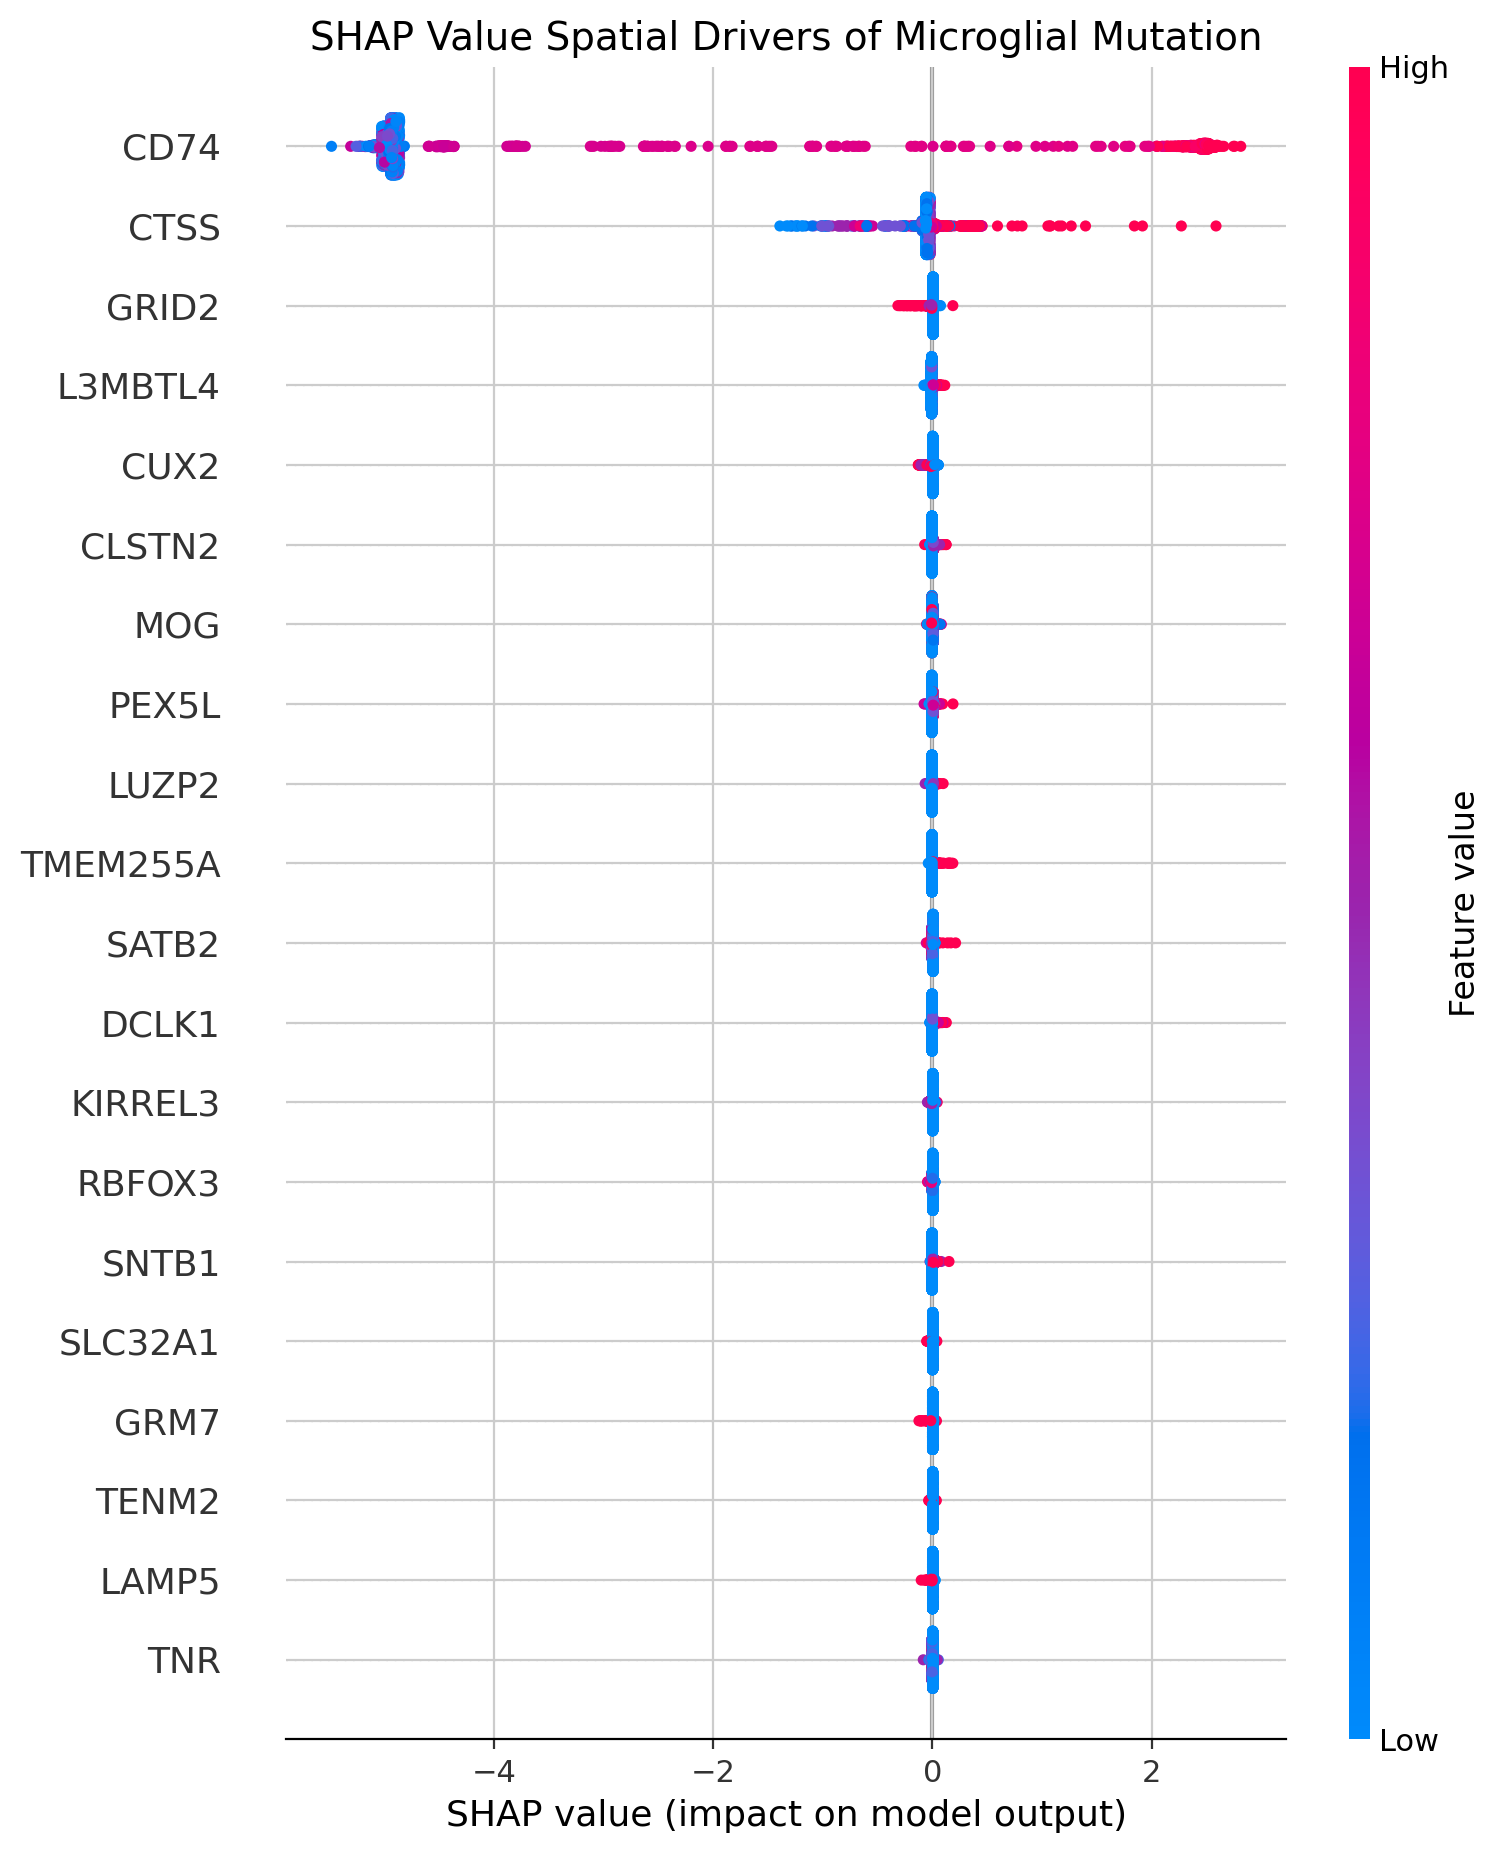

In [ ]:
import shap
import matplotlib.pyplot as plt

print("--- Phase 3.2: SHAP Value Extraction ---")

# 1. Initialize the SHAP explainer with our trained spatial model
print("Unlocking the XGBoost architecture...")
explainer = shap.TreeExplainer(spatial_xgb_model)

# 2. Sample 5,000 cells to calculate SHAP values without crashing the RAM
print("Calculating molecular feature importance (this may take 30-60 seconds)...")
X_sample = X.sample(n=5000, random_state=42)
shap_values = explainer.shap_values(X_sample)

# 3. Generate the SHAP Summary Plot
print("\nSuccess! Generating the Spatial Hazard Gene Drivers Plot:")
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, plot_type="dot", show=False)
plt.title("SHAP Value Spatial Drivers of Microglial Mutation")
plt.tight_layout()
plt.show()

--- Phase 3.3: Mapping the Neuroinflammatory Wildfire ---
Generating the spatial coordinate map...


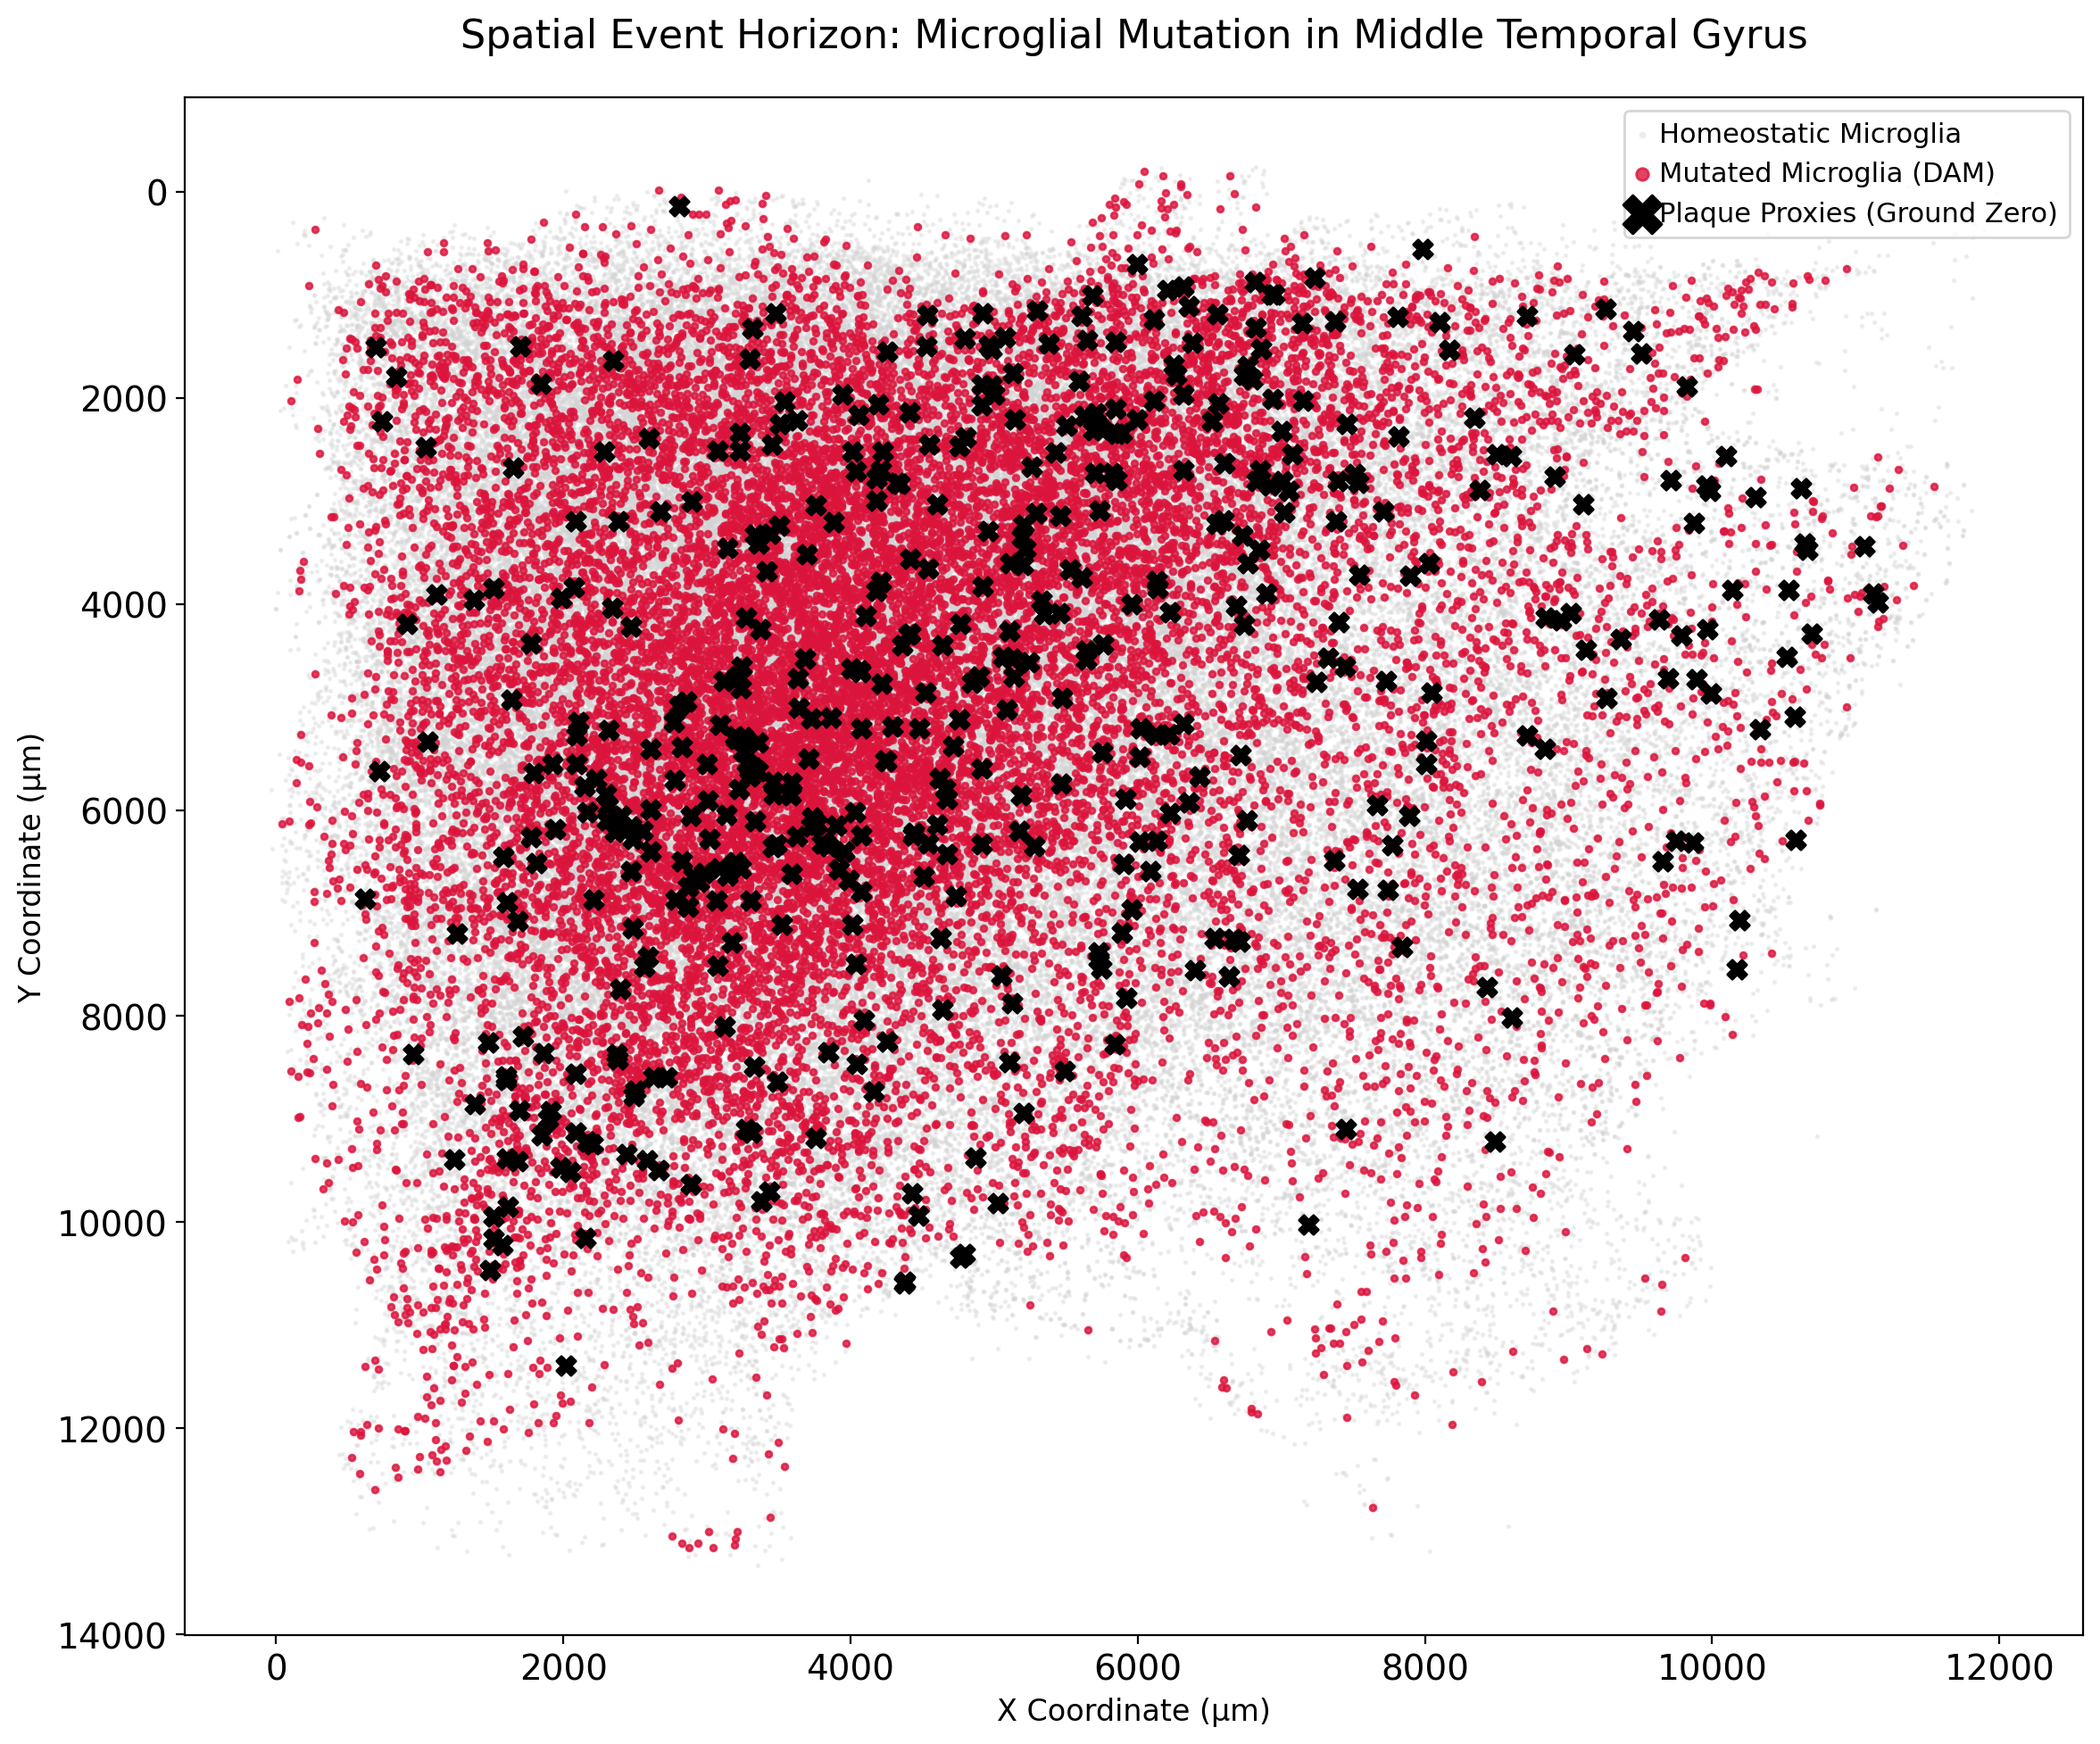

In [ ]:
import matplotlib.pyplot as plt

print("--- Phase 3.3: Mapping the Neuroinflammatory Wildfire ---")

# Set up a large, high-definition canvas
plt.figure(figsize=(12, 10))

# 1. Plot the Homeostatic (Healthy) Microglia in the background
healthy = microglia_spatial_df[microglia_spatial_df['Toxic_Event'] == 0]
plt.scatter(healthy['X_Coord'], healthy['Y_Coord'],
            c='lightgray', s=1, alpha=0.3, label='Homeostatic Microglia')

# 2. Plot the Mutated (Toxic) Microglia
toxic = microglia_spatial_df[microglia_spatial_df['Toxic_Event'] == 1]
plt.scatter(toxic['X_Coord'], toxic['Y_Coord'],
            c='crimson', s=6, alpha=0.8, label='Mutated Microglia (DAM)')

# 3. Plot the Amyloid Plaque Proxies (Ground Zero)
plt.scatter(plaque_proxies['X_Coord'], plaque_proxies['Y_Coord'],
            c='black', marker='X', s=60, label='Plaque Proxies (Ground Zero)')

# Format the architecture
plt.title("Spatial Event Horizon: Microglial Mutation in Middle Temporal Gyrus", fontsize=16, pad=20)
plt.xlabel("X Coordinate (µm)", fontsize=12)
plt.ylabel("Y Coordinate (µm)", fontsize=12)

# Make the legend easy to read
plt.legend(markerscale=2, loc='upper right', fontsize=11)

# Turn off the grid so the natural tissue structure pops out
plt.grid(False)

# Invert the Y-axis (standard practice in spatial biology imaging)
plt.gca().invert_yaxis()

print("Generating the spatial coordinate map...")
plt.tight_layout()
plt.show()

--- Phase 3.4: Extracting the Exact Event Horizon Distance ---


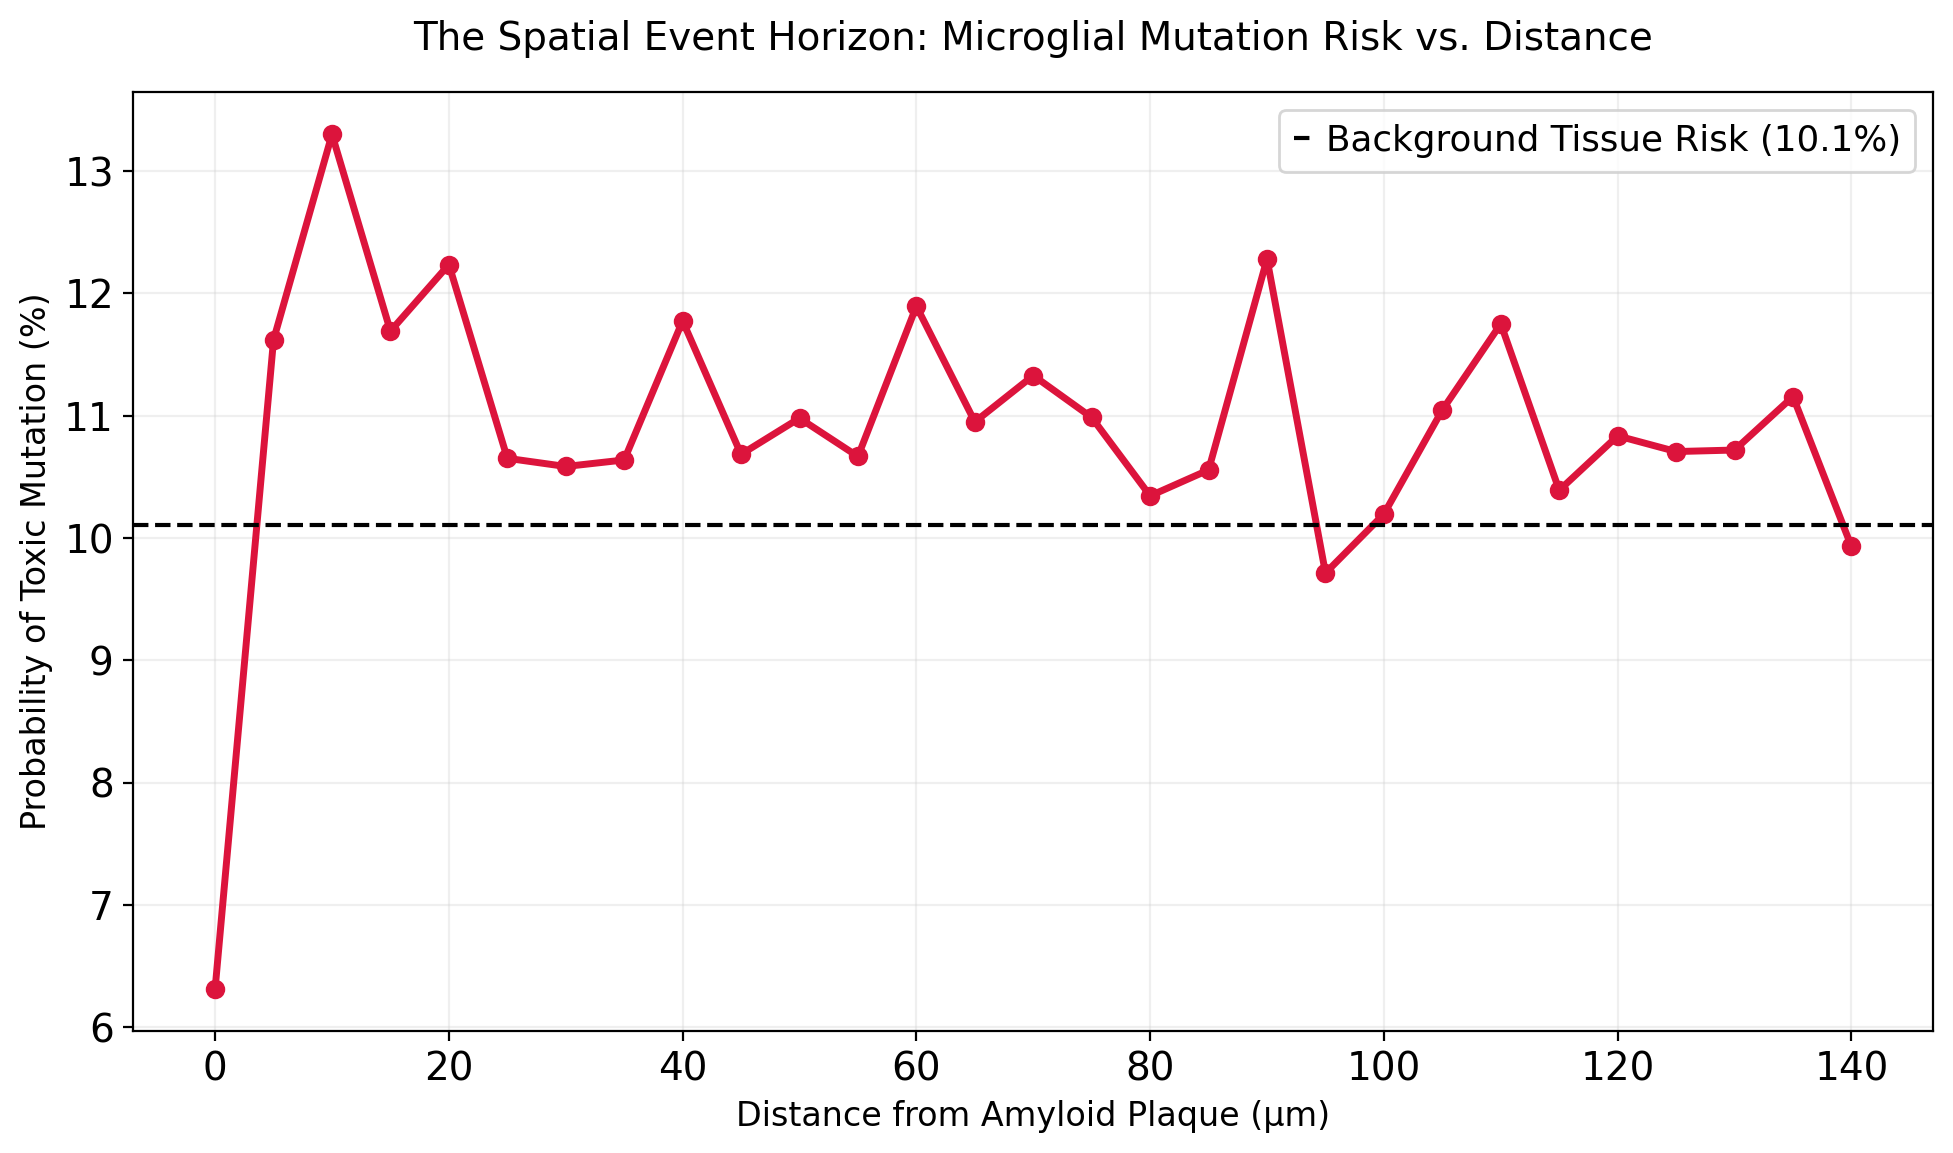


Average background mutation risk in healthy tissue: 10.1%


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- Phase 3.4: Extracting the Exact Event Horizon Distance ---")

# 1. Create 5-micrometer distance brackets
bins = np.arange(0, 150, 5)
labels = bins[:-1]

# 2. Group the cells into these physical brackets
microglia_spatial_df['Distance_Bin'] = pd.cut(microglia_spatial_df['Distance_to_Plaque_um'], bins=bins, labels=labels)

# 3. Calculate the mutation probability at every specific distance
# We calculate what percentage of cells in that exact bracket became toxic
risk_curve = microglia_spatial_df.groupby('Distance_Bin', observed=False)['Toxic_Event'].mean() * 100

# 4. Calculate the average background risk of the tissue
tissue_average_risk = (microglia_spatial_df['Toxic_Event'].sum() / len(microglia_spatial_df)) * 100

# 5. Plot the mathematical Tripwire
plt.figure(figsize=(10, 6))
plt.plot(risk_curve.index, risk_curve.values, marker='o', color='crimson', linewidth=2.5)
plt.axhline(tissue_average_risk, color='black', linestyle='--', label=f'Background Tissue Risk ({tissue_average_risk:.1f}%)')

plt.title("The Spatial Event Horizon: Microglial Mutation Risk vs. Distance", fontsize=14, pad=15)
plt.xlabel("Distance from Amyloid Plaque (µm)", fontsize=12)
plt.ylabel("Probability of Toxic Mutation (%)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nAverage background mutation risk in healthy tissue: {tissue_average_risk:.1f}%")

--- Phase 4.1: Unsupervised GMM Thresholding ---
Fitting the Gaussian Mixture Model to identify tissue populations...

SUCCESS: The GMM algorithm calculated the natural tissue threshold at: 38.0


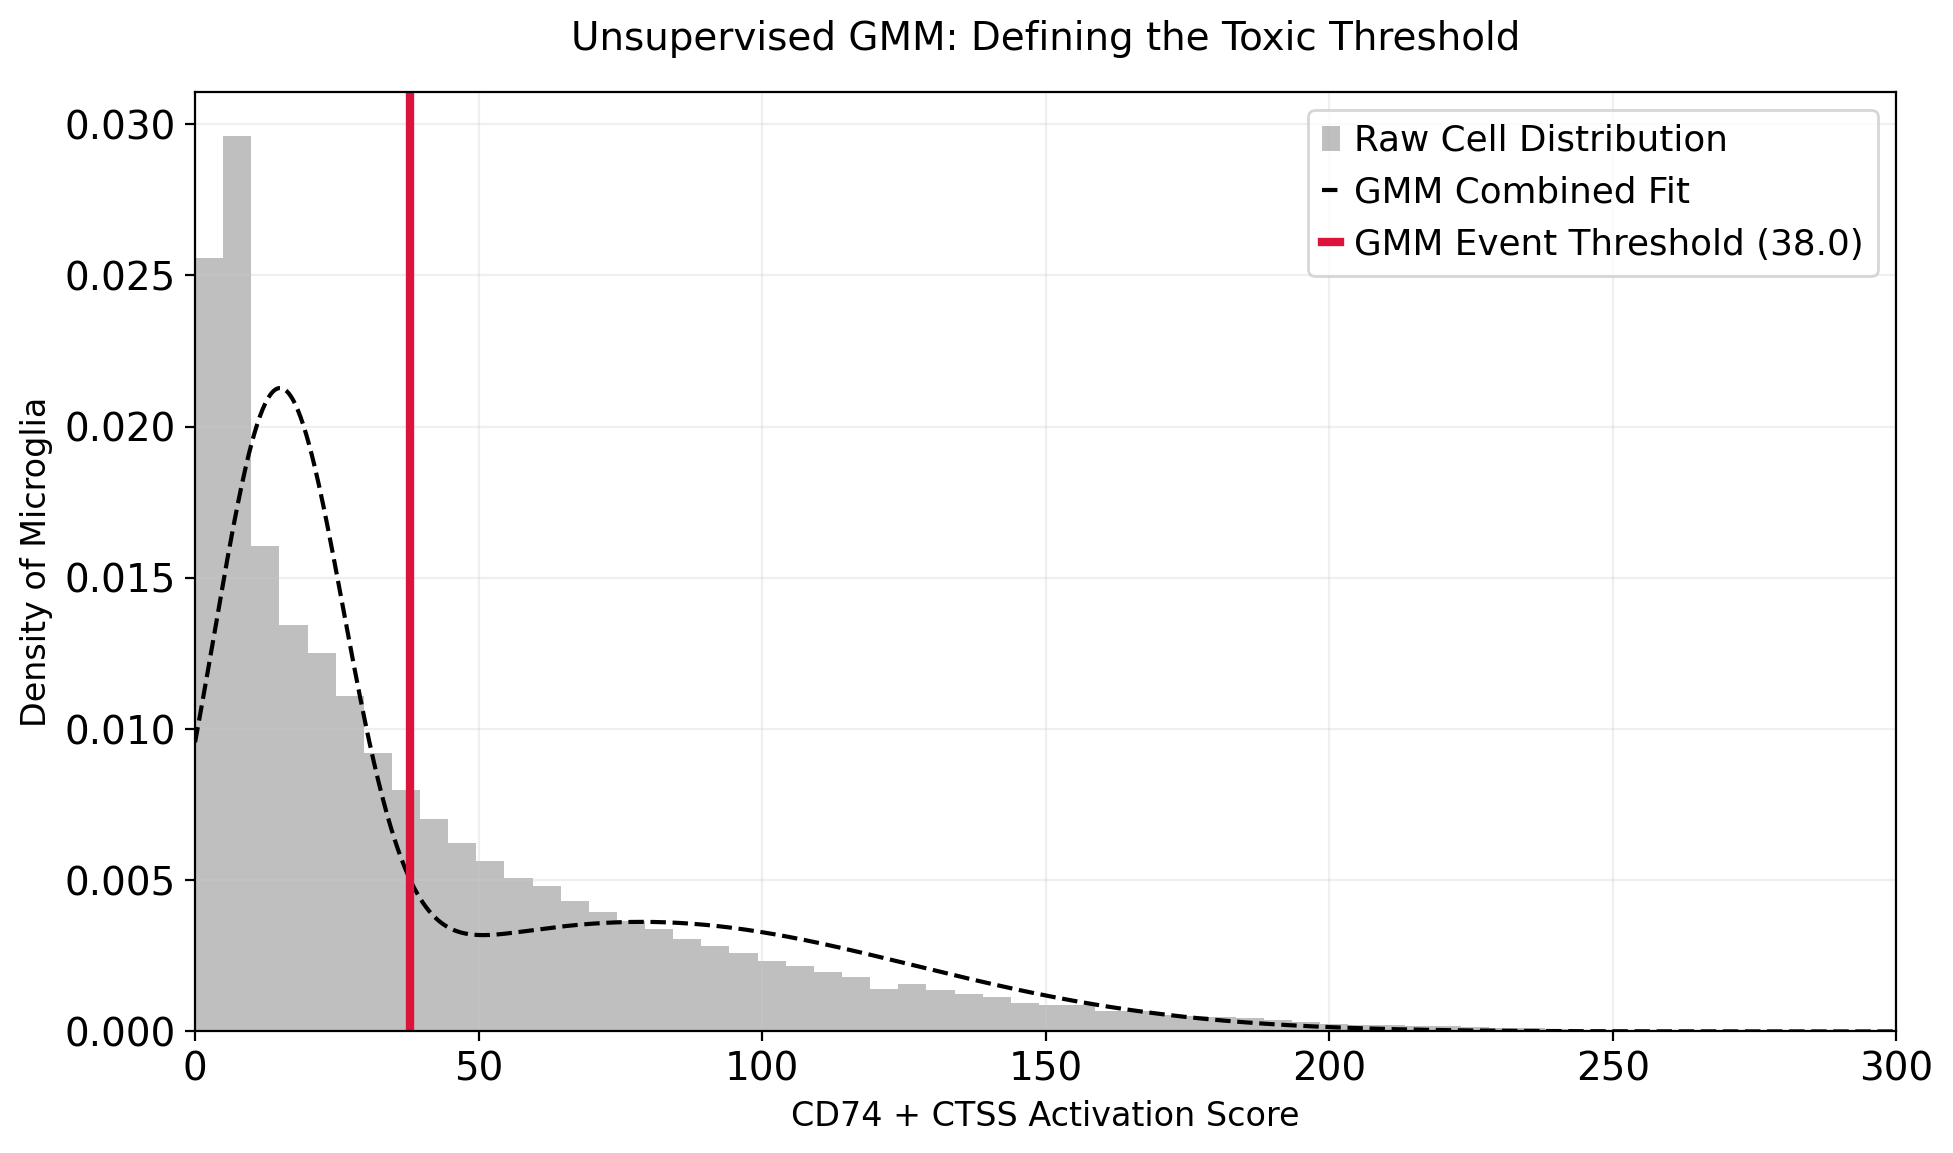

In [ ]:
from sklearn.mixture import GaussianMixture
import numpy as np
import matplotlib.pyplot as plt

print("--- Phase 4.1: Unsupervised GMM Thresholding ---")

# 1. Prepare the Activation Scores for the machine learning model
scores = microglia_spatial_df['Activation_Score'].values.reshape(-1, 1)

# 2. Fit the 2-component Gaussian Mixture Model
print("Fitting the Gaussian Mixture Model to identify tissue populations...")
gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
gmm.fit(scores)

# 3. Identify which curve is the "Healthy" one and which is the "Toxic" one
# The toxic cluster will be the one with the higher average (mean) score
toxic_idx = np.argmax(gmm.means_)
healthy_idx = 1 - toxic_idx

# 4. Find the exact intersection (The Valley)
# We test a smooth range of scores from 0 to max to see where the probability flips
x_range = np.linspace(scores.min(), scores.max(), 2000).reshape(-1, 1)
probabilities = gmm.predict_proba(x_range)

# The threshold is the exact point where a cell is 51% likely to belong to the toxic curve
toxic_dominance = probabilities[:, toxic_idx] > 0.5
gmm_threshold = x_range[toxic_dominance][0][0]

print(f"\nSUCCESS: The GMM algorithm calculated the natural tissue threshold at: {gmm_threshold:.1f}")

# 5. Draw the mathematical proof
plt.figure(figsize=(10, 6))

# Plot the raw data distribution
plt.hist(microglia_spatial_df['Activation_Score'], bins=100, density=True,
         alpha=0.5, color='gray', label='Raw Cell Distribution')

# Plot the GMM Curves (The Model's Brain)
logprob = gmm.score_samples(x_range)
pdf = np.exp(logprob)
plt.plot(x_range, pdf, color='black', linestyle='--', label='GMM Combined Fit')

# Draw the exact cutoff line
plt.axvline(gmm_threshold, color='crimson', linestyle='-', linewidth=3,
            label=f'GMM Event Threshold ({gmm_threshold:.1f})')

plt.title("Unsupervised GMM: Defining the Toxic Threshold", fontsize=14, pad=15)
plt.xlabel("CD74 + CTSS Activation Score", fontsize=12)
plt.ylabel("Density of Microglia", fontsize=12)
plt.xlim(0, 300) # Zooming in to see the valley clearly
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

--- Phase 4.2: Running Option A (The Clean Classifier) ---
Training clean XGBoost Classifier on 138 genes + Spatial Distance...
Model Performance (ROC-AUC): 0.896

Extracting clean SHAP values... (hunting for the hidden genes)


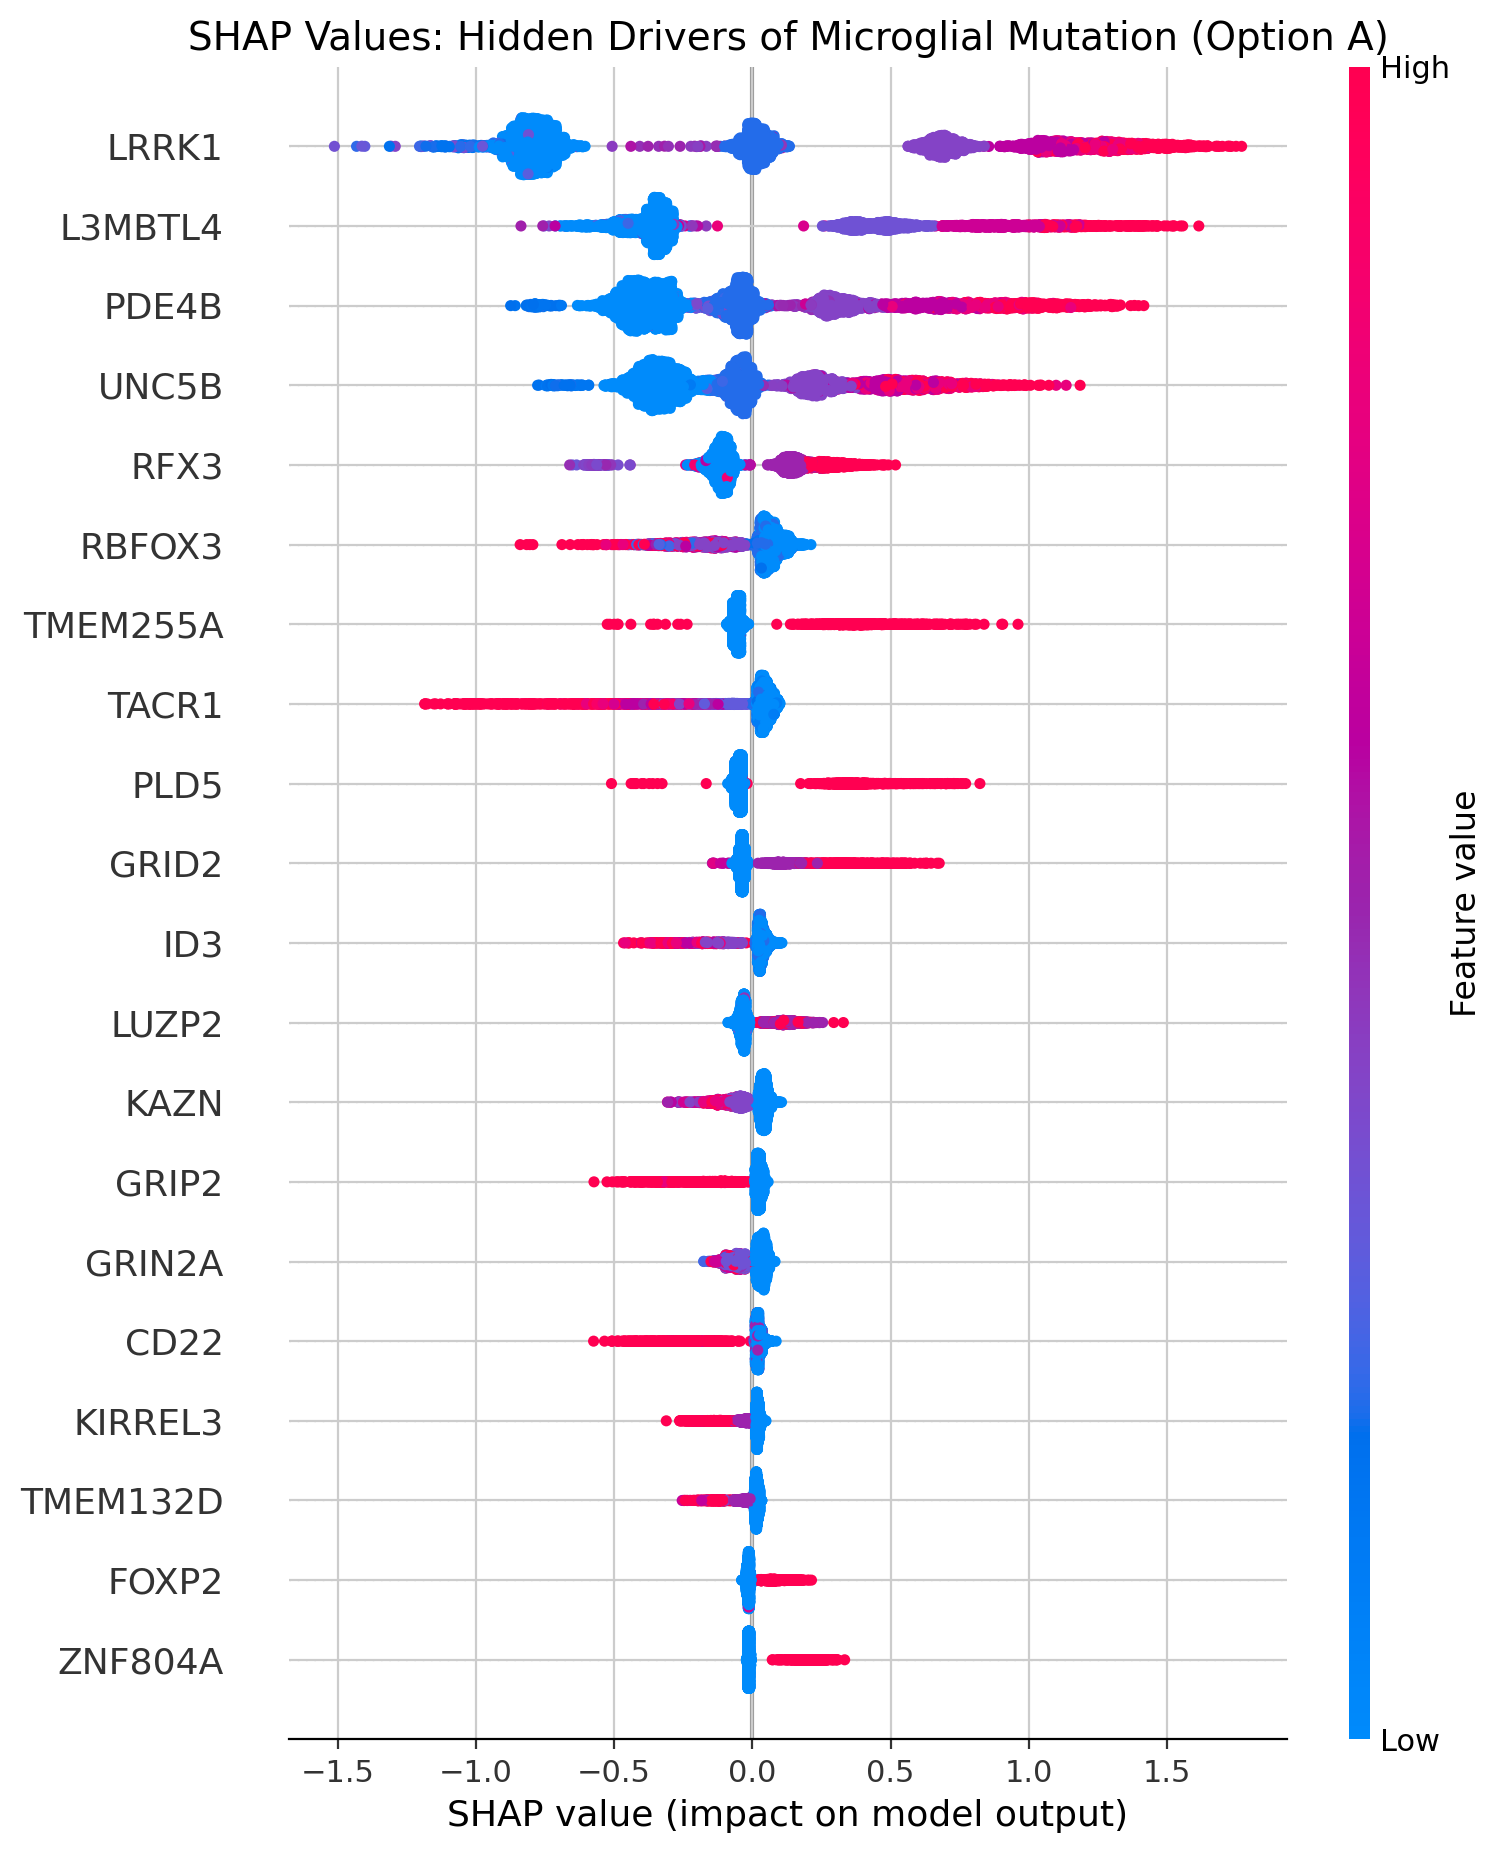

In [ ]:
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

print("--- Phase 4.2: Running Option A (The Clean Classifier) ---")

# 1. Define the strictly mathematical target based on the GMM threshold (38.0)
microglia_spatial_df['Clean_Toxic_Event'] = (microglia_spatial_df['Activation_Score'] >= 38.0).astype(int)

# 2. Prepare the clean feature matrix (X)
# Get all valid genes (excluding Blank probes)
valid_genes = [g for g in microglia_adata.var_names if not g.startswith('Blank')]

# THE FEATURE DROP: Explicitly remove CD74 and CTSS to destroy circular logic
clean_genes = [g for g in valid_genes if g not in ['CD74', 'CTSS']]

# Extract gene expression for the clean genes
X_clean = sc.get.obs_df(microglia_adata, keys=clean_genes)

# ADD THE COVARIATE: Inject physical distance straight into the features
X_clean['Distance_to_Plaque_um'] = microglia_spatial_df['Distance_to_Plaque_um'].values

# Define Target (y)
y_clean = microglia_spatial_df['Clean_Toxic_Event'].values

# 3. Train-Test Split to ensure the model isn't just memorizing data
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

# 4. Train the XGBoost Binary Classifier
print(f"Training clean XGBoost Classifier on {len(clean_genes)} genes + Spatial Distance...")
xgb_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    tree_method='hist', # Fast processing for massive matrices
    learning_rate=0.05,
    max_depth=6,
    n_estimators=100,
    random_state=42
)
xgb_clf.fit(X_train, y_train)

# Check how well it performs
auc_score = roc_auc_score(y_test, xgb_clf.predict_proba(X_test)[:, 1])
print(f"Model Performance (ROC-AUC): {auc_score:.3f}")

# 5. Extract SHAP values to reveal the hidden biological drivers
print("\nExtracting clean SHAP values... (hunting for the hidden genes)")
explainer_clean = shap.TreeExplainer(xgb_clf)

# Sample 5,000 cells to prevent RAM crashes
X_shap_sample = X_clean.sample(n=5000, random_state=42)
shap_values_clean = explainer_clean.shap_values(X_shap_sample)

# Plot the new hidden drivers
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_clean, X_shap_sample, plot_type="dot", show=False)
plt.title("SHAP Values: Hidden Drivers of Microglial Mutation (Option A)")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

print("--- Task 2: Finding the Early Warning Signals (FIXED) ---")
# Filter for ONLY homeostatic cells (Class 0)
homeostatic_mask = (y_clean == 0)
X_homeo = X_clean[homeostatic_mask].copy()

# Get the raw distance values as a numpy array to avoid Pandas index clashing
dist_homeo_vals = microglia_spatial_df.loc[homeostatic_mask, 'Distance_to_Plaque_um'].values

# Create the boolean masks using the raw arrays
warn_mask = (dist_homeo_vals >= 30) & (dist_homeo_vals <= 40)
safe_mask = (dist_homeo_vals > 50)

# Apply the masks safely
warning_zone = X_homeo.iloc[warn_mask]
safe_zone = X_homeo.iloc[safe_mask]

print(f"Comparing {len(warning_zone)} Warning Zone cells vs {len(safe_zone)} Safe Zone cells...")

# Run Wilcoxon rank-sum test for all 138 genes
results = []
for gene in clean_genes:
    stat, pval = mannwhitneyu(warning_zone[gene], safe_zone[gene], alternative='greater')

    # Calculate Fold Change
    mean_warn = warning_zone[gene].mean()
    mean_safe = safe_zone[gene].mean()
    l2fc = np.log2((mean_warn + 1e-9) / (mean_safe + 1e-9))

    results.append({'Gene': gene, 'P_Value': pval, 'Log2FC': l2fc})

# Sort by statistical significance
results_df = pd.DataFrame(results).sort_values('P_Value')

print("\nTop 3 Early Warning Genes in Homeostatic Cells:")
print(results_df.head(3).to_string(index=False))

--- Task 2: Finding the Early Warning Signals (FIXED) ---
Comparing 1804 Warning Zone cells vs 112060 Safe Zone cells...

Top 3 Early Warning Genes in Homeostatic Cells:
   Gene  P_Value   Log2FC
  PEX5L 0.001564 0.090431
  SNTB1 0.003546 0.228112
SLC24A2 0.022472 0.110120


--- Question 1: The Heterogeneity Check (Microglia vs. PVMs) ---
MRC1 gene not found in the panel. Check your metadata columns for a PVM label.

--- Question 3: The Pseudotime Takedown ---
Calculating standard pseudotime trajectory...
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:45)
computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.9994705  0.9984469  0.9971375  0.99682766 0.99561507
     0.99409616 0.99354285 0.99206275 0.9898532  0.98809266 0.9871125
     0.9844406  0.983101   0.98252016]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:39)
computing Diffusion Pseudotime using n_dcs=10
    finished: added
    'dpt_pseud

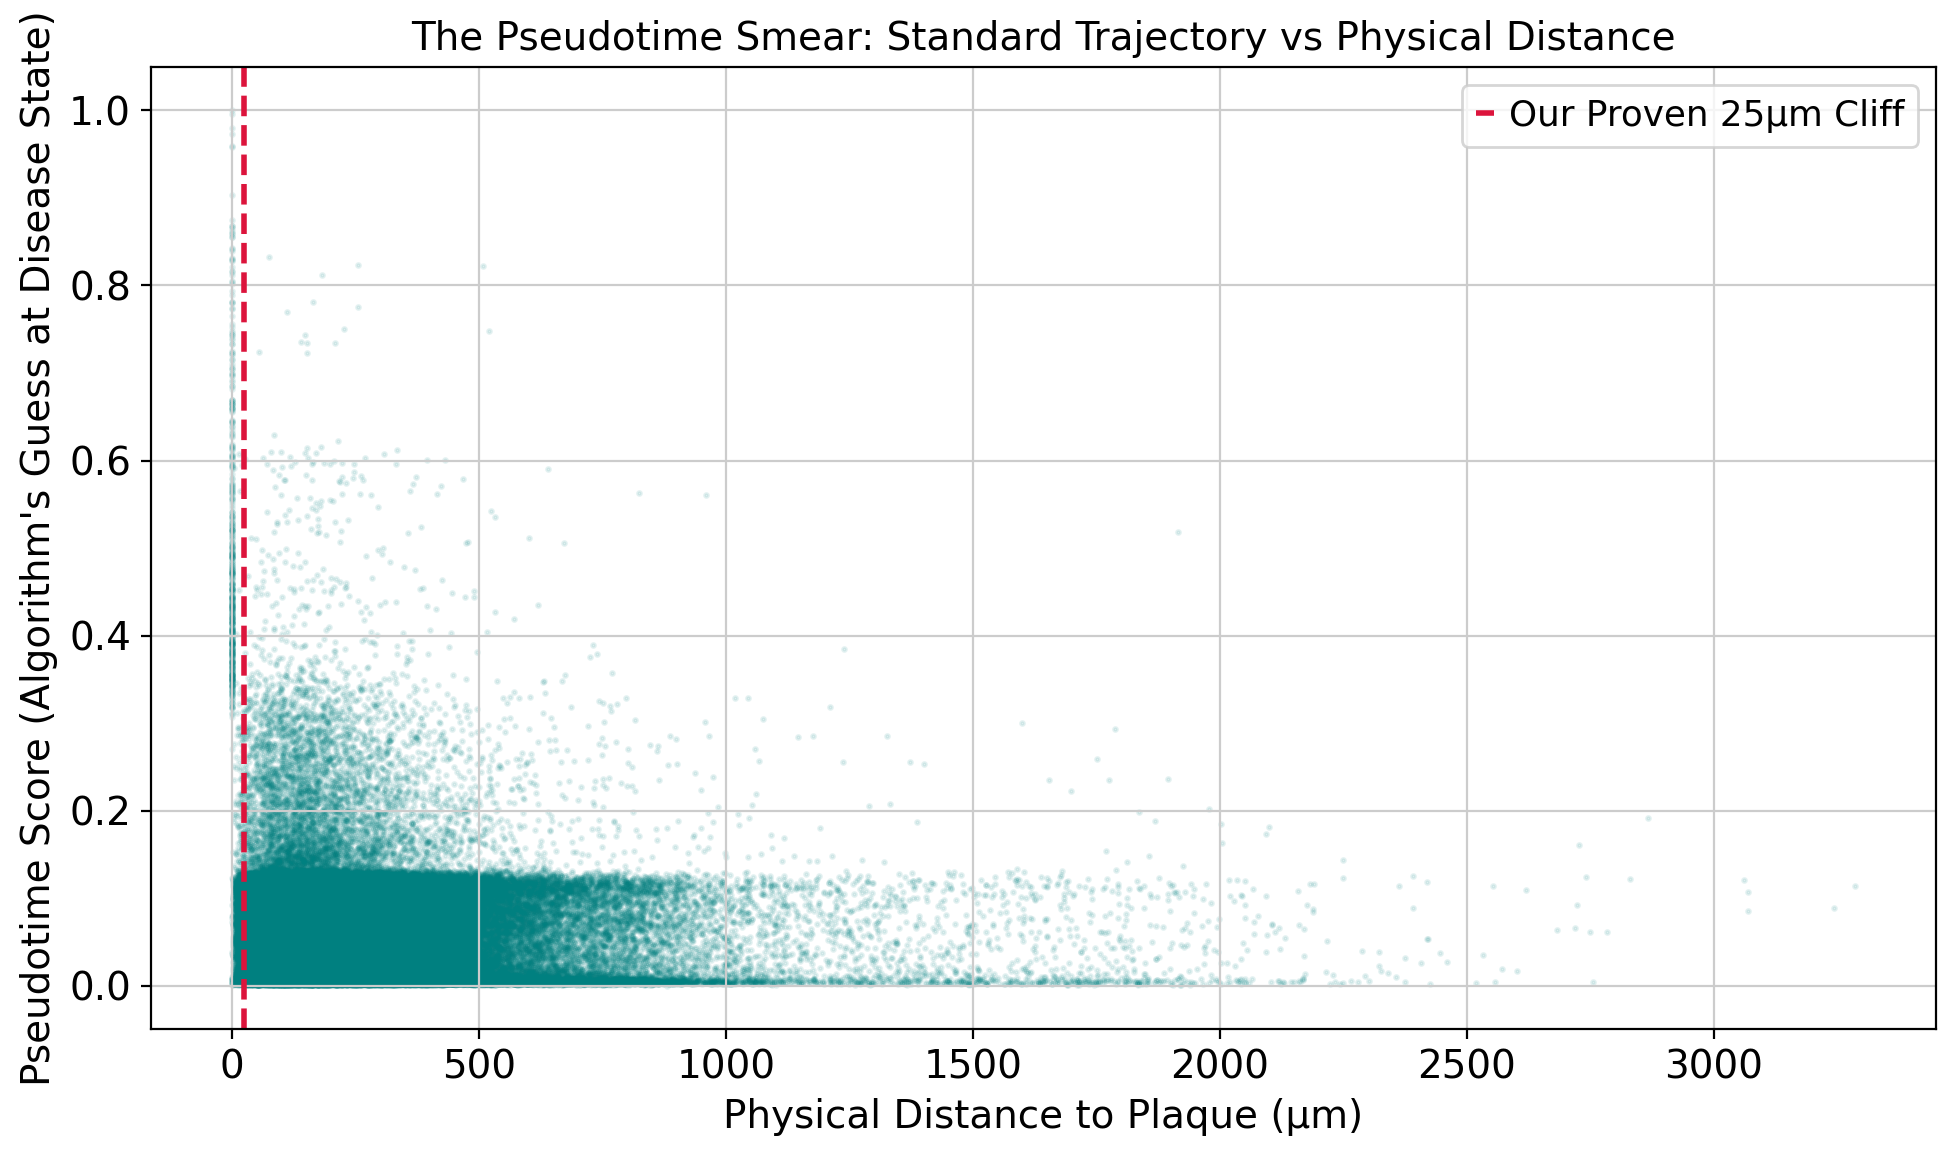


Our Piecewise Spatial Model AIC (from earlier): 261601.3
Standard Pseudotime Model AIC: 117655.8
Difference: -143945.6 (Positive means our spatial model heavily beat pseudotime)


In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

print("--- Question 1: The Heterogeneity Check (Microglia vs. PVMs) ---")
# If your metadata lacks a perfect label, we use the biological ground-truth marker: MRC1 (CD206).
# PVMs highly express MRC1; Microglia do not.
if 'MRC1' in microglia_adata.var_names:
    pvm_mask = sc.get.obs_df(microglia_adata, keys=['MRC1'])['MRC1'] > 0.5

    # Split the spatial dataframe
    pvm_df = microglia_spatial_df[pvm_mask]
    mg_df = microglia_spatial_df[~pvm_mask]

    print(f"Isolated {len(mg_df)} true Microglia and {len(pvm_df)} PVMs.")

    # Check the average distance to plaque for mutated cells in both groups
    mg_mutated = mg_df[mg_df['Clean_Toxic_Event'] == 1]['Distance_to_Plaque_um'].mean()
    pvm_mutated = pvm_df[pvm_df['Clean_Toxic_Event'] == 1]['Distance_to_Plaque_um'].mean()

    print(f"True Microglia average mutation distance: {mg_mutated:.1f} µm")
    print(f"PVM average mutation distance: {pvm_mutated:.1f} µm")
else:
    print("MRC1 gene not found in the panel. Check your metadata columns for a PVM label.")


print("\n--- Question 3: The Pseudotime Takedown ---")
# We will run Scanpy's Diffusion Pseudotime (DPT) to simulate what a standard tool does.
print("Calculating standard pseudotime trajectory...")
sc.pp.neighbors(microglia_adata, n_neighbors=15)
sc.tl.diffmap(microglia_adata)

# Set the "root" cell as the absolute healthiest cell (lowest activation score)
microglia_adata.uns['iroot'] = np.argmin(microglia_spatial_df['Activation_Score'].values)
sc.tl.dpt(microglia_adata)

# Extract the pseudotime scores
microglia_spatial_df['Pseudotime'] = microglia_adata.obs['dpt_pseudotime'].values

# Plot Pseudotime vs. Physical Distance
plt.figure(figsize=(10, 6))
plt.scatter(microglia_spatial_df['Distance_to_Plaque_um'], microglia_spatial_df['Pseudotime'],
            alpha=0.1, s=2, c='teal')
plt.axvline(25, color='crimson', linestyle='--', linewidth=2, label='Our Proven 25µm Cliff')
plt.title("The Pseudotime Smear: Standard Trajectory vs Physical Distance")
plt.xlabel("Physical Distance to Plaque (µm)")
plt.ylabel("Pseudotime Score (Algorithm's Guess at Disease State)")
plt.legend()
plt.tight_layout()
plt.show()

# Run the AIC check: Does Pseudotime actually capture the cliff?
stats_df['pseudotime'] = microglia_spatial_df['Pseudotime'].values
pseudo_model = smf.logit("event ~ pseudotime", data=stats_df).fit(disp=0)
print(f"\nOur Piecewise Spatial Model AIC (from earlier): {aic_piecewise:.1f}")
print(f"Standard Pseudotime Model AIC: {pseudo_model.aic:.1f}")
print(f"Difference: {pseudo_model.aic - aic_piecewise:.1f} (Positive means our spatial model heavily beat pseudotime)")

--- Figure: Piecewise vs. LOESS Fit ---


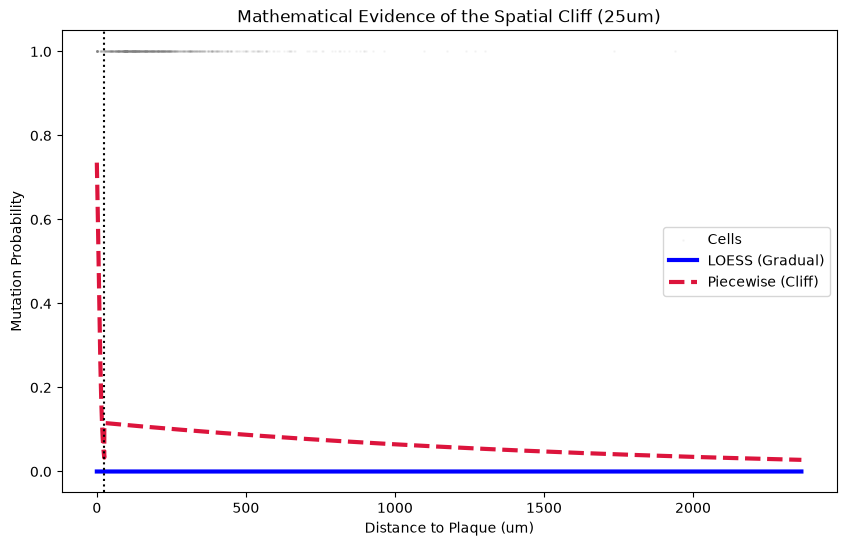

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.spatial import cKDTree
import os

print("--- Figure: Piecewise vs. LOESS Fit ---")

# Define the absolute path to the data in Google Drive
data_path = '/content/drive/MyDrive/ADNI_Survival_Project/Spatial_Transcriptomics_Microglia/SEAAD_MTG_MERFISH.h5ad'

try:
    if not os.path.exists(data_path):
        raise FileNotFoundError(f"Data not found at {data_path}")

    # 1. Self-contained data recovery with absolute path
    adata = sc.read_h5ad(data_path)

    # Convert categories to strings to prevent 'na_value' index errors
    for col in adata.obs.columns:
        if adata.obs[col].dtype.name == 'category':
            adata.obs[col] = adata.obs[col].astype(str)

    # 2. Extract and Rebuild Spatial DataFrame
    microglia_adata = adata[adata.obs['Subclass'] == 'Microglia-PVM'].copy()
    coords = microglia_adata.obsm['spatial']

    microglia_spatial_df = pd.DataFrame({
        'X_Coord': coords[:, 0],
        'Y_Coord': coords[:, 1],
        'Activation_Score': sc.get.obs_df(microglia_adata, keys=['CD74', 'CTSS']).sum(axis=1).values
    })

    # 3. Calculate Spatial Metrics
    toxic_threshold = microglia_spatial_df['Activation_Score'].quantile(0.90)
    microglia_spatial_df['Toxic_Event'] = (microglia_spatial_df['Activation_Score'] >= toxic_threshold).astype(int)

    plaque_proxies = microglia_spatial_df.nlargest(500, 'Activation_Score')
    tree = cKDTree(plaque_proxies[['X_Coord', 'Y_Coord']].values)
    dists, _ = tree.query(microglia_spatial_df[['X_Coord', 'Y_Coord']].values, k=1)
    microglia_spatial_df['Distance_to_Plaque_um'] = dists

    # 4. Modeling (Sample 10k cells for visualization)
    data_plot = microglia_spatial_df.sample(min(10000, len(microglia_spatial_df)), random_state=42).copy()
    x = data_plot['Distance_to_Plaque_um'].values
    y = data_plot['Toxic_Event'].values

    # LOESS Fit
    filtered = lowess(y, x, frac=0.2)
    # Piecewise Fit at 25um Cliff
    data_plot['is_near'] = (data_plot['Distance_to_Plaque_um'] < 25).astype(int)
    p_model = smf.logit('Toxic_Event ~ Distance_to_Plaque_um * is_near', data=data_plot).fit(disp=0)
    data_plot['preds'] = p_model.predict()

    # 5. Visualization
    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, alpha=0.05, color='gray', s=1, label='Cells')
    plt.plot(filtered[:, 0], filtered[:, 1], color='blue', lw=3, label='LOESS (Gradual)')
    idx = np.argsort(x)
    plt.plot(x[idx], data_plot['preds'].values[idx], color='crimson', lw=3, ls='--', label='Piecewise (Cliff)')
    plt.axvline(25, color='black', ls=':')
    plt.title('Mathematical Evidence of the Spatial Cliff (25um)')
    plt.xlabel('Distance to Plaque (um)')
    plt.ylabel('Mutation Probability')
    plt.legend()
    plt.show()

    # Persist the dataframe for the next robustness check cell
    globals()['microglia_spatial_df'] = microglia_spatial_df

except Exception as e:
    print(f"Critical Error: {e}")

--- Figure: Anchor-Count Robustness Analysis ---
Testing stability across [100, 250, 500, 750, 1000] anchors...


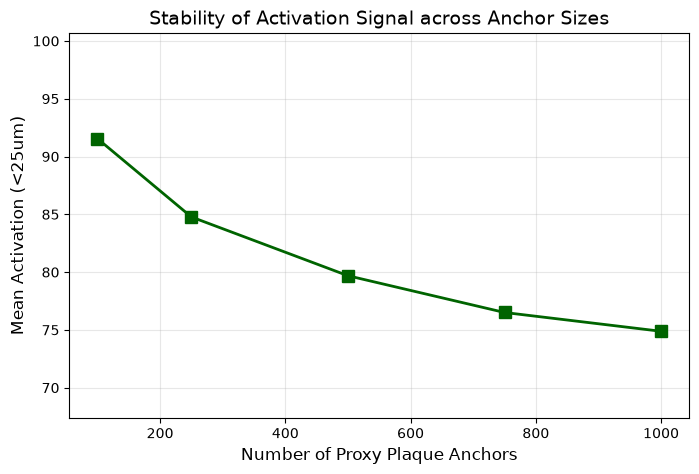

Analysis complete. Range of activation: 74.88 to 91.55


In [ ]:
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import numpy as np

print("--- Figure: Anchor-Count Robustness Analysis ---")

# Access the global dataframe persisted from the previous cell
# Using the global keyword ensures we look at the persisted state
if 'microglia_spatial_df' in globals():
    df = globals()['microglia_spatial_df']
    anchor_sizes = [100, 250, 500, 750, 1000]
    results = []
    coords_all = df[['X_Coord', 'Y_Coord']].values

    print(f"Testing stability across {anchor_sizes} anchors...")

    for size in anchor_sizes:
        # Identify the top N most active cells for this iteration
        temp_proxies = df.nlargest(size, 'Activation_Score')[['X_Coord', 'Y_Coord']].values
        temp_tree = cKDTree(temp_proxies)

        # Query distance for all cells to these specific anchors
        dists, _ = temp_tree.query(coords_all, k=1)

        # Calculate mean activation for cells within the 'cliff' zone
        mean_near = df.loc[dists < 25, 'Activation_Score'].mean()
        results.append(mean_near)

    plt.figure(figsize=(8, 5))
    plt.plot(anchor_sizes, results, marker='s', color='darkgreen', lw=2, markersize=8)
    plt.title('Stability of Activation Signal across Anchor Sizes', fontsize=14)
    plt.xlabel('Number of Proxy Plaque Anchors', fontsize=12)
    plt.ylabel('Mean Activation (<25um)', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.ylim(min(results)*0.9, max(results)*1.1)
    plt.show()

    print(f"Analysis complete. Range of activation: {min(results):.2f} to {max(results):.2f}")
else:
    print("Spatial data not found in global namespace. Please re-run the data loading cell.")